In [1]:
# ============================================================
# Section 1 : Import Libraries
# ============================================================

import os
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings("ignore")

print("Libraries Imported Successfully")

Libraries Imported Successfully


In [2]:
# ============================================================
# Section 2 : Project Paths
# ============================================================

PROJECT_DIR = r"D:/Brac thesis"

# ============================================================
# Dataset Directories
# ============================================================

DATASET_DIR = os.path.join(
    PROJECT_DIR,
    "dataset"
)

PROCESSED_DATASET_DIR = os.path.join(
    DATASET_DIR,
    "processed"
)

METADATA_DIR = os.path.join(
    DATASET_DIR,
    "metadata"
)

# ============================================================
# Models Directory
# ============================================================

MODELS_DIR = os.path.join(
    PROJECT_DIR,
    "models"
)

# ============================================================
# Results Directory
# ============================================================

RESULTS_DIR = os.path.join(
    PROJECT_DIR,
    "results",
    "comparison"
)

CONFUSION_MATRIX_DIR = os.path.join(
    RESULTS_DIR,
    "confusion_matrices"
)

ROC_CURVE_DIR = os.path.join(
    RESULTS_DIR,
    "roc_curves"
)

METRICS_DIR = os.path.join(
    RESULTS_DIR,
    "metrics"
)

# ============================================================
# Create Directories
# ============================================================

for directory in [

    RESULTS_DIR,

    CONFUSION_MATRIX_DIR,

    ROC_CURVE_DIR,

    METRICS_DIR

]:

    os.makedirs(

        directory,

        exist_ok=True

    )

# ============================================================
# Dataset Files
# ============================================================

TEST_CSV = os.path.join(

    PROCESSED_DATASET_DIR,

    "test.csv"

)

METADATA_PATH = os.path.join(

    METADATA_DIR,

    "metadata.json"

)

print("Project Paths Ready")

Project Paths Ready


In [3]:
# ============================================================
# Section 3 : Load Metadata
# ============================================================

with open(

    METADATA_PATH,

    "r"

) as file:

    metadata = json.load(

        file

    )

# ============================================================
# Image Information
# ============================================================

IMAGE_HEIGHT = metadata["image_height"]

IMAGE_WIDTH = metadata["image_width"]

CHANNELS = metadata["channels"]

# ============================================================
# Dataset Information
# ============================================================

TRAIN_SIZE = metadata["train_size"]

VALIDATION_SIZE = metadata["validation_size"]

TEST_SIZE = metadata["test_size"]

TOTAL_IMAGES = metadata["total_images"]

NUM_CLASSES = metadata["total_labels"]

# ============================================================
# Label Information
# ============================================================

CLASS_NAMES = metadata["labels"]

LABEL_TO_INDEX = metadata["label_to_index"]

INDEX_TO_LABEL = {

    int(index): label

    for index, label in metadata["index_to_label"].items()

}

# ============================================================
# Display Metadata
# ============================================================

print(f"Image Size        : {IMAGE_HEIGHT} × {IMAGE_WIDTH}")

print(f"Channels          : {CHANNELS}")

print(f"Training Split    : {TRAIN_SIZE:.0%}")

print(f"Validation Split  : {VALIDATION_SIZE:.0%}")

print(f"Testing Split     : {TEST_SIZE:.0%}")

print(f"Total Images      : {TOTAL_IMAGES}")

print(f"Total Classes     : {NUM_CLASSES}")

print()

print("Class Labels")

print("-" * 40)

for index, label in INDEX_TO_LABEL.items():

    print(f"{index:2d} : {label}")

print()

print("Metadata Loaded Successfully")

Image Size        : 224 × 224
Channels          : 3
Training Split    : 70%
Validation Split  : 15%
Testing Split     : 15%
Total Images      : 8275
Total Classes     : 12

Class Labels
----------------------------------------
 0 : Acne_Mild
 1 : Acne_Moderate
 2 : Acne_Severe
 3 : Eczema_Mild
 4 : Eczema_Moderate
 5 : Eczema_Severe
 6 : Normal_dry
 7 : Normal_normal
 8 : Normal_oily
 9 : burn_Mild
10 : burn_Moderate
11 : burn_Severe

Metadata Loaded Successfully


In [4]:
# ============================================================
# Section 4 : Load Test Dataset
# ============================================================

test_df = pd.read_csv(

    TEST_CSV

)

print(

    f"Total Test Images : {len(test_df)}"

)

# ============================================================
# Image Loading Function
# ============================================================

def load_image(

    image_path,

    label

):

    image = tf.io.read_file(

        image_path

    )

    image = tf.io.decode_image(

        image,

        channels=CHANNELS,

        expand_animations=False

    )

    image = tf.image.resize(

        image,

        (

            IMAGE_HEIGHT,

            IMAGE_WIDTH

        )

    )

    image = tf.cast(

        image,

        tf.float32

    )

    label = tf.one_hot(

        label,

        depth=NUM_CLASSES,

        dtype=tf.float32

    )

    return image, label

print("Image Loader Ready")

# ============================================================
# Prepare Test Dataset
# ============================================================

test_dataset = tf.data.Dataset.from_tensor_slices(

    (

        test_df["filepath"].values,

        test_df["label"].map(

            LABEL_TO_INDEX

        ).values

    )

)

test_dataset = test_dataset.map(

    load_image,

    num_parallel_calls=tf.data.AUTOTUNE

)

test_dataset = test_dataset.batch(

    32

)

test_dataset = test_dataset.prefetch(

    tf.data.AUTOTUNE

)

print("Test Dataset Ready")

Total Test Images : 1242
Image Loader Ready
Test Dataset Ready


In [5]:
# ============================================================
# Section 5 : Load Models
# ============================================================

models = {}

for model_folder in sorted(

    os.listdir(

        MODELS_DIR

    )

):

    folder_path = os.path.join(

        MODELS_DIR,

        model_folder

    )

    if not os.path.isdir(

        folder_path

    ):

        continue

    model_files = [

        file

        for file in os.listdir(

            folder_path

        )

        if file.startswith(

            "skin_condition_identifier"

        )

        and file.endswith(

            ".keras"

        )

    ]

    if not model_files:

        continue

    model_path = os.path.join(

        folder_path,

        model_files[0]

    )

    models[model_folder] = keras.models.load_model(

        model_path

    )

    print(

        f"Loaded : {model_folder}"

    )

print()

print(

    f"Total Models Loaded : {len(models)}"

)

Loaded : efficientnetb0
Loaded : mobilenetv2
Loaded : resnet50

Total Models Loaded : 3


In [6]:
# ============================================================
# Section 6 : Evaluate Models
# ============================================================

results = []

predictions = {}

true_labels = np.concatenate(

    [

        np.argmax(

            labels.numpy(),

            axis=1

        )

        for _, labels in test_dataset

    ]

)

print("Starting Model Evaluation...\n")

for model_name, model in models.items():

    print(f"Evaluating : {model_name}")

    # --------------------------------------------------------
    # Measure Inference Time
    # --------------------------------------------------------

    start_time = time.time()

    prediction_probabilities = model.predict(

        test_dataset,

        verbose=0

    )

    end_time = time.time()

    total_time = end_time - start_time

    average_time = total_time / len(test_df)

    # --------------------------------------------------------
    # Convert Probabilities to Labels
    # --------------------------------------------------------

    predicted_labels = np.argmax(

        prediction_probabilities,

        axis=1

    )

    predictions[model_name] = {

        "probabilities": prediction_probabilities,

        "predicted_labels": predicted_labels

    }

    # --------------------------------------------------------
    # Calculate Metrics
    # --------------------------------------------------------

    accuracy = accuracy_score(

        true_labels,

        predicted_labels

    )

    precision = precision_score(

        true_labels,

        predicted_labels,

        average="weighted",

        zero_division=0

    )

    recall = recall_score(

        true_labels,

        predicted_labels,

        average="weighted",

        zero_division=0

    )

    f1 = f1_score(

        true_labels,

        predicted_labels,

        average="weighted",

        zero_division=0

    )

    auc = roc_auc_score(

        tf.keras.utils.to_categorical(

            true_labels,

            NUM_CLASSES

        ),

        prediction_probabilities,

        multi_class="ovr",

        average="weighted"

    )

    # --------------------------------------------------------
    # Store Results
    # --------------------------------------------------------

    results.append(

        {

            "Model": model_name,

            "Accuracy": accuracy,

            "Precision": precision,

            "Recall": recall,

            "F1-Score": f1,

            "ROC-AUC": auc,

            "Inference Time (ms/image)": average_time * 1000

        }

    )

    print(

        f"Accuracy : {accuracy:.4f}"

    )

    print(

        f"Precision : {precision:.4f}"

    )

    print(

        f"Recall : {recall:.4f}"

    )

    print(

        f"F1-Score : {f1:.4f}"

    )

    print(

        f"ROC-AUC : {auc:.4f}"

    )

    print(

        f"Inference : {average_time * 1000:.2f} ms/image"

    )

    print("-" * 50)

print("\nAll Models Evaluated Successfully")

Starting Model Evaluation...

Evaluating : efficientnetb0
Accuracy : 0.7295
Precision : 0.7301
Recall : 0.7295
F1-Score : 0.7256
ROC-AUC : 0.9707
Inference : 22.79 ms/image
--------------------------------------------------
Evaluating : mobilenetv2
Accuracy : 0.7126
Precision : 0.7162
Recall : 0.7126
F1-Score : 0.7119
ROC-AUC : 0.9702
Inference : 17.12 ms/image
--------------------------------------------------
Evaluating : resnet50
Accuracy : 0.7432
Precision : 0.7462
Recall : 0.7432
F1-Score : 0.7403
ROC-AUC : 0.9748
Inference : 47.68 ms/image
--------------------------------------------------

All Models Evaluated Successfully


In [7]:
# ============================================================
# Section 7 : Classification Reports
# ============================================================

print("Generating Classification Reports...\n")

for model_name in models.keys():

    print("=" * 70)

    print(f"Model : {model_name}")

    print("=" * 70)

    predicted_labels = predictions[model_name]["predicted_labels"]

    report = classification_report(

        true_labels,

        predicted_labels,

        target_names=CLASS_NAMES,

        output_dict=True,

        zero_division=0

    )

    report_df = pd.DataFrame(

        report

    ).transpose()

    print(

        report_df.round(4)

    )

    report_path = os.path.join(

        METRICS_DIR,

        f"{model_name}_classification_report.csv"

    )

    report_df.to_csv(

        report_path,

        index=True

    )

    print()

    print(

        f"Saved : {report_path}"

    )

    print()

Generating Classification Reports...

Model : efficientnetb0
                 precision  recall  f1-score    support
Acne_Mild           0.7788  0.8351    0.8060    97.0000
Acne_Moderate       0.7059  0.6186    0.6593    97.0000
Acne_Severe         0.7818  0.8776    0.8269    98.0000
Eczema_Mild         0.6406  0.8367    0.7257    98.0000
Eczema_Moderate     0.5444  0.5000    0.5213    98.0000
Eczema_Severe       0.7241  0.6429    0.6811    98.0000
Normal_dry          0.7791  0.5877    0.6700   114.0000
Normal_normal       0.7871  0.8325    0.8092   191.0000
Normal_oily         0.7838  0.8631    0.8215   168.0000
burn_Mild           0.7460  0.5875    0.6573    80.0000
burn_Moderate       0.6104  0.6438    0.6267    73.0000
burn_Severe         0.8000  0.6667    0.7273    30.0000
accuracy            0.7295  0.7295    0.7295     0.7295
macro avg           0.7235  0.7077    0.7110  1242.0000
weighted avg        0.7301  0.7295    0.7256  1242.0000

Saved : D:/Brac thesis\results\comparison\

Generating Confusion Matrices...



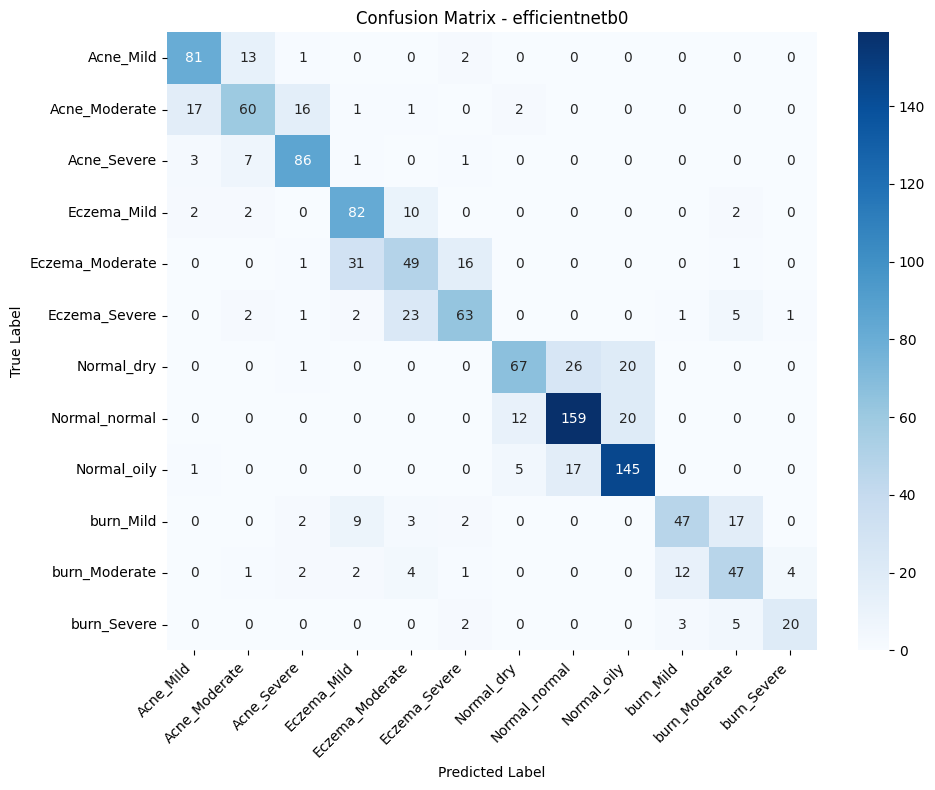

Saved : D:/Brac thesis\results\comparison\confusion_matrices\efficientnetb0_confusion_matrix.png


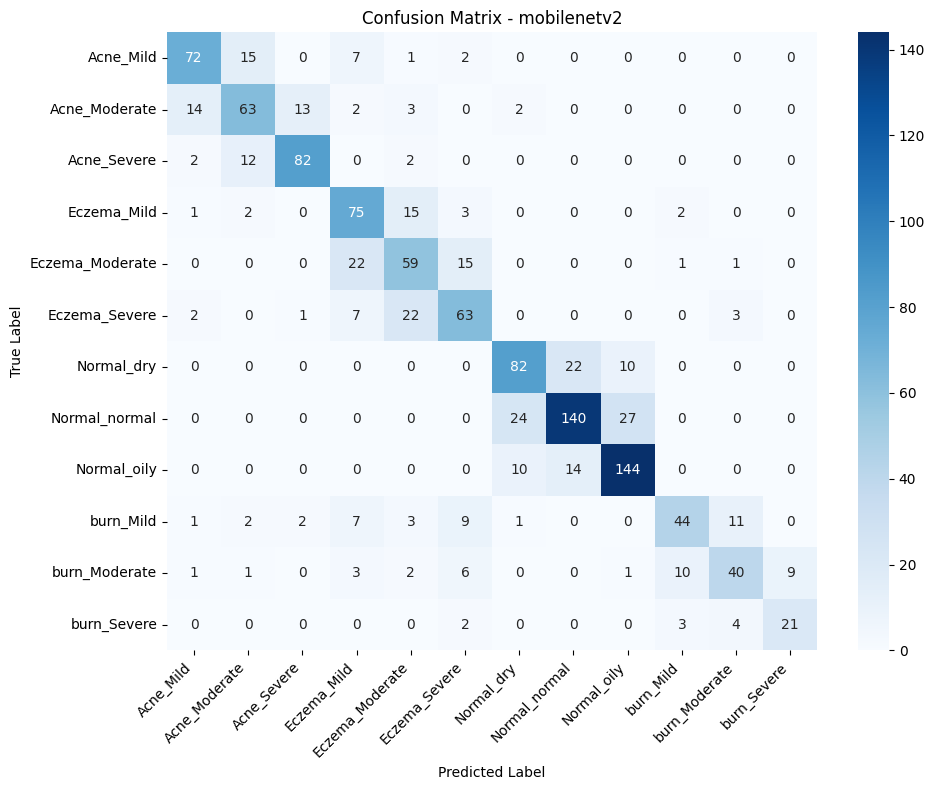

Saved : D:/Brac thesis\results\comparison\confusion_matrices\mobilenetv2_confusion_matrix.png


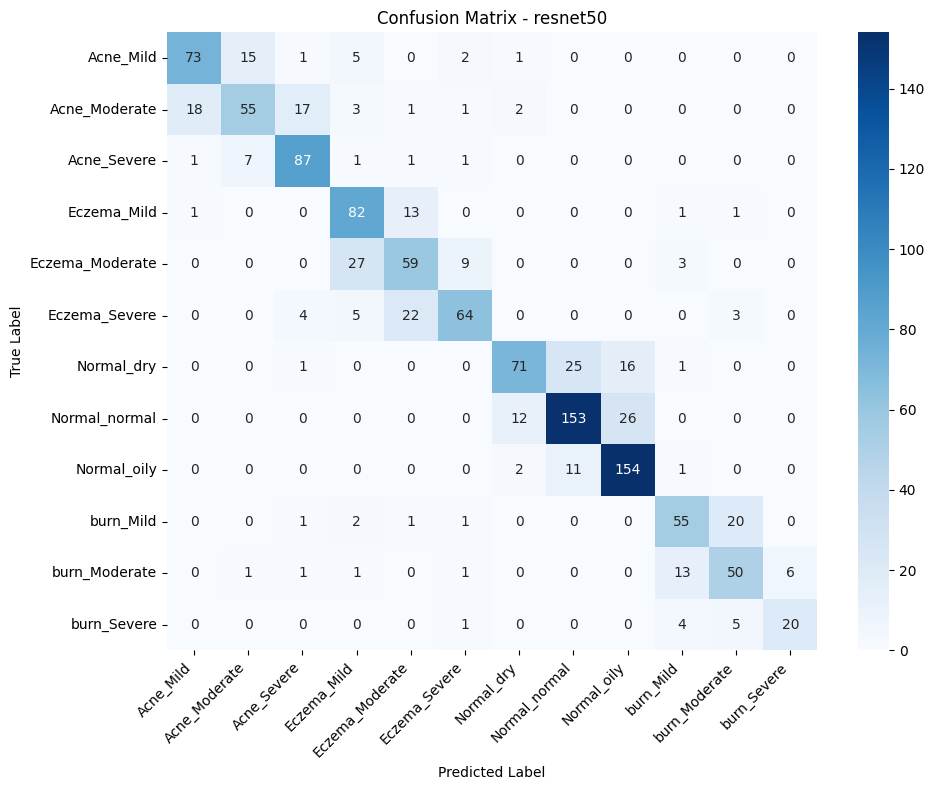

Saved : D:/Brac thesis\results\comparison\confusion_matrices\resnet50_confusion_matrix.png

All Confusion Matrices Generated Successfully


In [8]:
# ============================================================
# Section 8 : Confusion Matrices
# ============================================================

print("Generating Confusion Matrices...\n")

for model_name in models.keys():

    predicted_labels = predictions[model_name]["predicted_labels"]

    cm = confusion_matrix(

        true_labels,

        predicted_labels

    )

    plt.figure(

        figsize=(10, 8)

    )

    sns.heatmap(

        cm,

        annot=True,

        fmt="d",

        cmap="Blues",

        xticklabels=CLASS_NAMES,

        yticklabels=CLASS_NAMES

    )

    plt.title(

        f"Confusion Matrix - {model_name}"

    )

    plt.xlabel(

        "Predicted Label"

    )

    plt.ylabel(

        "True Label"

    )

    plt.xticks(

        rotation=45,

        ha="right"

    )

    plt.yticks(

        rotation=0

    )

    plt.tight_layout()

    save_path = os.path.join(

        CONFUSION_MATRIX_DIR,

        f"{model_name}_confusion_matrix.png"

    )

    plt.savefig(

        save_path,

        dpi=300,

        bbox_inches="tight"

    )

    plt.show()

    plt.close()

    print(

        f"Saved : {save_path}"

    )

print()

print("All Confusion Matrices Generated Successfully")

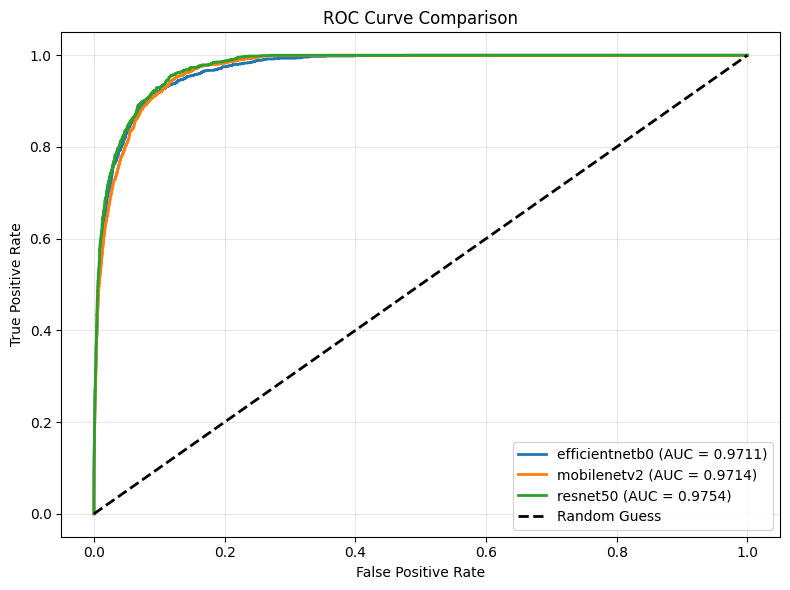

Saved : D:/Brac thesis\results\comparison\roc_curves\roc_curve_comparison.png


In [9]:
# ============================================================
# Section 9 : ROC Curves
# ============================================================

from sklearn.metrics import roc_curve, auc

plt.figure(

    figsize=(8, 6)

)

for model_name in models.keys():

    probabilities = predictions[model_name][

        "probabilities"

    ]

    fpr, tpr, _ = roc_curve(

        tf.keras.utils.to_categorical(

            true_labels,

            NUM_CLASSES

        ).ravel(),

        probabilities.ravel()

    )

    roc_auc = auc(

        fpr,

        tpr

    )

    plt.plot(

        fpr,

        tpr,

        linewidth=2,

        label=f"{model_name} (AUC = {roc_auc:.4f})"

    )

plt.plot(

    [0, 1],

    [0, 1],

    linestyle="--",

    linewidth=2,

    color="black",

    label="Random Guess"

)

plt.title(

    "ROC Curve Comparison"

)

plt.xlabel(

    "False Positive Rate"

)

plt.ylabel(

    "True Positive Rate"

)

plt.legend(

    loc="lower right"

)

plt.grid(

    alpha=0.3

)

plt.tight_layout()

save_path = os.path.join(

    ROC_CURVE_DIR,

    "roc_curve_comparison.png"

)

plt.savefig(

    save_path,

    dpi=300,

    bbox_inches="tight"

)

plt.show()

plt.close()

print(f"Saved : {save_path}")

In [10]:
# ============================================================
# Section 10 : Model Performance Comparison
# ============================================================

comparison_df = pd.DataFrame(

    results

)

comparison_df = comparison_df.sort_values(

    by=[

        "Accuracy",

        "F1-Score",

        "ROC-AUC"

    ],

    ascending=False

).reset_index(

    drop=True

)

comparison_df.insert(

    0,

    "Rank",

    np.arange(

        1,

        len(comparison_df) + 1

    )

)

comparison_df = comparison_df.round(

    {

        "Accuracy": 4,

        "Precision": 4,

        "Recall": 4,

        "F1-Score": 4,

        "ROC-AUC": 4,

        "Inference Time (ms/image)": 2

    }

)

comparison_path = os.path.join(

    METRICS_DIR,

    "model_comparison.csv"

)

comparison_df.to_csv(

    comparison_path,

    index=False

)

print("=" * 90)

print("Model Performance Comparison")

print("=" * 90)

display(

    comparison_df

)

print()

print(f"Saved : {comparison_path}")

Model Performance Comparison


,Rank,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Inference Time (ms/image)
0,1,resnet50,0.7432,0.7462,0.7432,0.7403,0.9748,47.68
1,2,efficientnetb0,0.7295,0.7301,0.7295,0.7256,0.9707,22.79
2,3,mobilenetv2,0.7126,0.7162,0.7126,0.7119,0.9702,17.12



Saved : D:/Brac thesis\results\comparison\metrics\model_comparison.csv


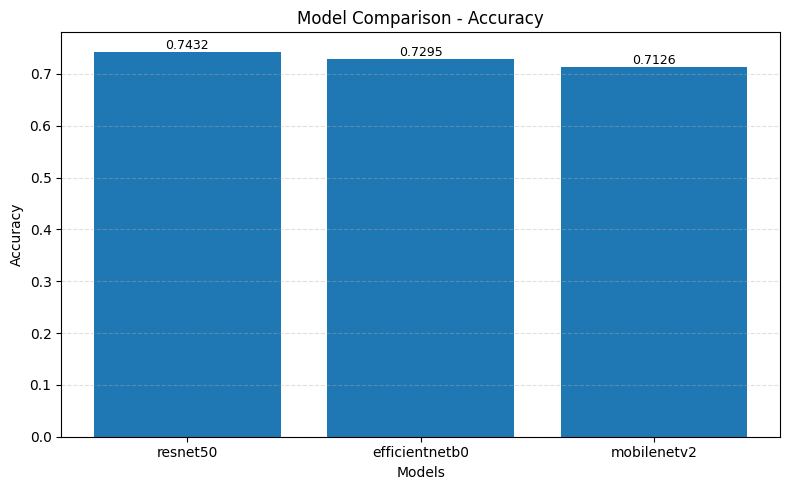

Saved : D:/Brac thesis\results\comparison\metrics\accuracy.png


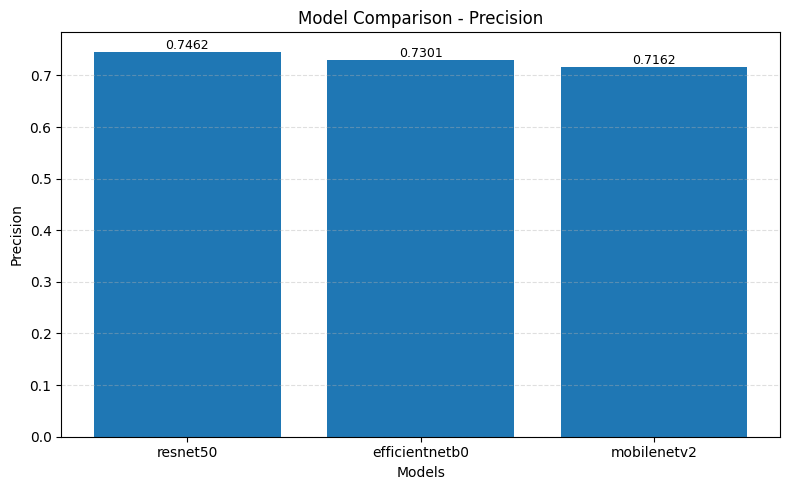

Saved : D:/Brac thesis\results\comparison\metrics\precision.png


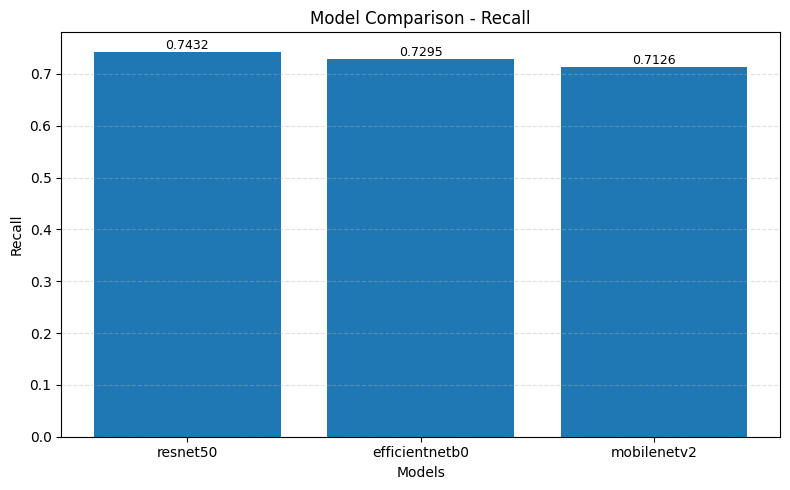

Saved : D:/Brac thesis\results\comparison\metrics\recall.png


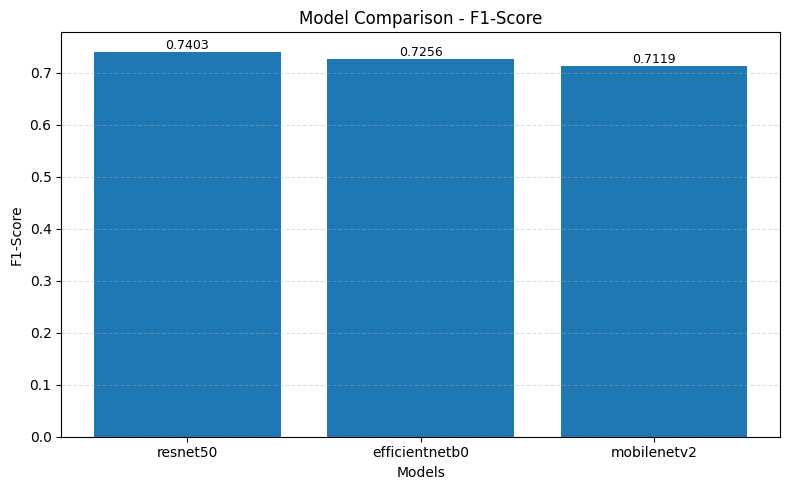

Saved : D:/Brac thesis\results\comparison\metrics\f1_score.png


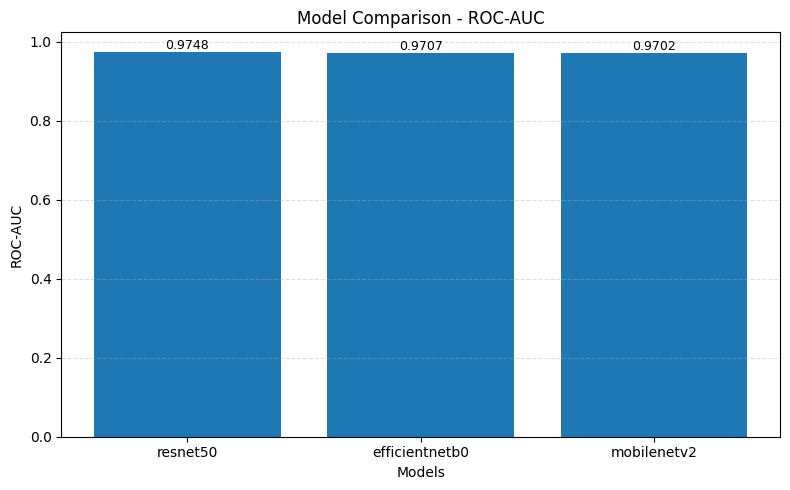

Saved : D:/Brac thesis\results\comparison\metrics\roc_auc.png


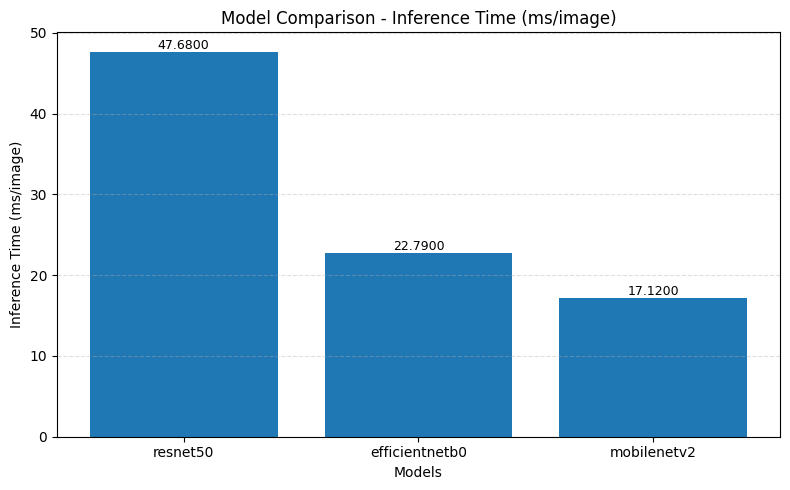

Saved : D:/Brac thesis\results\comparison\metrics\inference_time_ms_image.png

Performance Visualizations Generated Successfully


In [11]:
# ============================================================
# Section 11 : Performance Visualization
# ============================================================

metrics = [

    "Accuracy",

    "Precision",

    "Recall",

    "F1-Score",

    "ROC-AUC",

    "Inference Time (ms/image)"

]

for metric in metrics:

    plt.figure(

        figsize=(8, 5)

    )

    bars = plt.bar(

        comparison_df["Model"],

        comparison_df[metric]

    )

    plt.title(

        f"Model Comparison - {metric}"

    )

    plt.xlabel(

        "Models"

    )

    plt.ylabel(

        metric

    )

    plt.grid(

        axis="y",

        linestyle="--",

        alpha=0.4

    )

    # --------------------------------------------------------
    # Show values on top of bars
    # --------------------------------------------------------

    for bar in bars:

        height = bar.get_height()

        plt.text(

            bar.get_x() + bar.get_width() / 2,

            height,

            f"{height:.4f}",

            ha="center",

            va="bottom",

            fontsize=9

        )

    plt.tight_layout()

    save_path = os.path.join(

        METRICS_DIR,

        f"{metric.lower().replace(' ', '_').replace('-', '_').replace('(', '').replace(')', '').replace('/', '_')}.png"

    )

    plt.savefig(

        save_path,

        dpi=300,

        bbox_inches="tight"

    )

    plt.show()

    plt.close()

    print(

        f"Saved : {save_path}"

    )

print()

print("Performance Visualizations Generated Successfully")

In [12]:
# ============================================================
# Section 12 : Best Model Selection
# ============================================================

best_model = comparison_df.iloc[0]

print("=" * 70)

print("BEST MODEL")

print("=" * 70)

print(f"Model Name                : {best_model['Model']}")

print(f"Accuracy                  : {best_model['Accuracy']:.4f}")

print(f"Precision                 : {best_model['Precision']:.4f}")

print(f"Recall                    : {best_model['Recall']:.4f}")

print(f"F1-Score                  : {best_model['F1-Score']:.4f}")

print(f"ROC-AUC                   : {best_model['ROC-AUC']:.4f}")

print(f"Inference Time (ms/image) : {best_model['Inference Time (ms/image)']:.2f}")

print("=" * 70)

# ============================================================
# Save Best Model Information
# ============================================================

best_model_df = pd.DataFrame(

    [best_model]

)

save_path = os.path.join(

    METRICS_DIR,

    "best_model.csv"

)

best_model_df.to_csv(

    save_path,

    index=False

)

print()

print(f"Saved : {save_path}")

BEST MODEL
Model Name                : resnet50
Accuracy                  : 0.7432
Precision                 : 0.7462
Recall                    : 0.7432
F1-Score                  : 0.7403
ROC-AUC                   : 0.9748
Inference Time (ms/image) : 47.68

Saved : D:/Brac thesis\results\comparison\metrics\best_model.csv


In [13]:
# ============================================================
# Section 14 : Compare Training History
# ============================================================

histories = {}

for model_name in models.keys():

    history_path = os.path.join(

        MODELS_DIR,

        model_name,

        "training_history.json"

    )

    with open(

        history_path,

        "r"

    ) as file:

        histories[model_name] = json.load(

            file

        )

print("Training Histories Loaded Successfully")

Training Histories Loaded Successfully


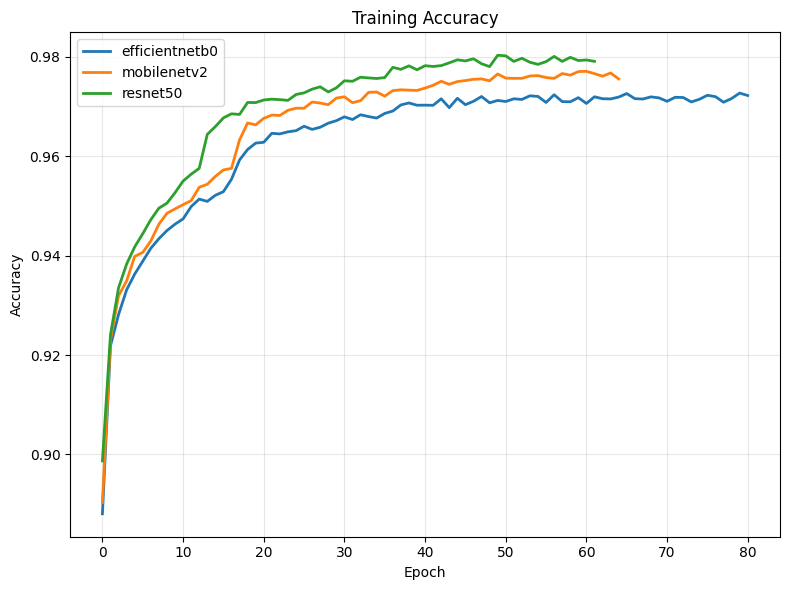

In [14]:
plt.figure(figsize=(8,6))

for model_name, history in histories.items():

    plt.plot(

        history["accuracy"],

        linewidth=2,

        label=model_name

    )

plt.title("Training Accuracy")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(

    os.path.join(

        METRICS_DIR,

        "training_accuracy_comparison.png"

    ),

    dpi=300

)

plt.show()

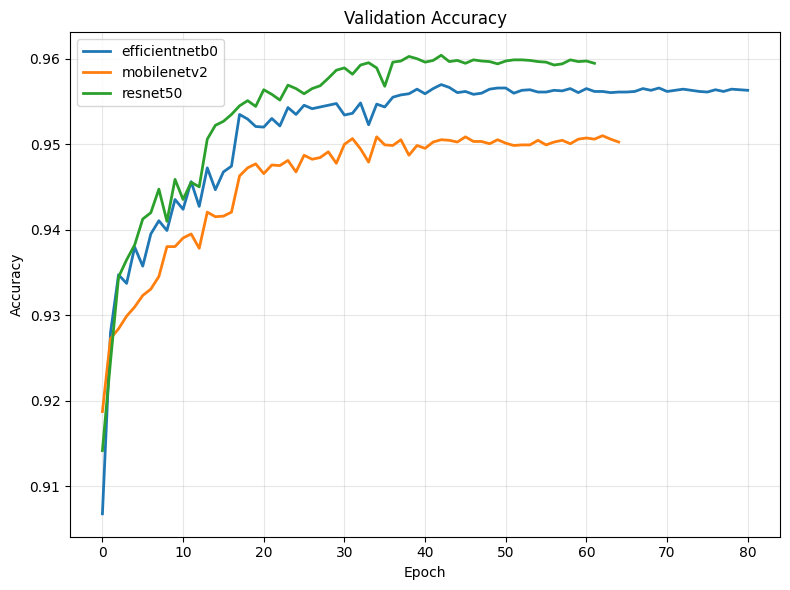

In [15]:
plt.figure(figsize=(8,6))

for model_name, history in histories.items():

    plt.plot(

        history["val_accuracy"],

        linewidth=2,

        label=model_name

    )

plt.title("Validation Accuracy")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(

    os.path.join(

        METRICS_DIR,

        "validation_accuracy_comparison.png"

    ),

    dpi=300

)

plt.show()

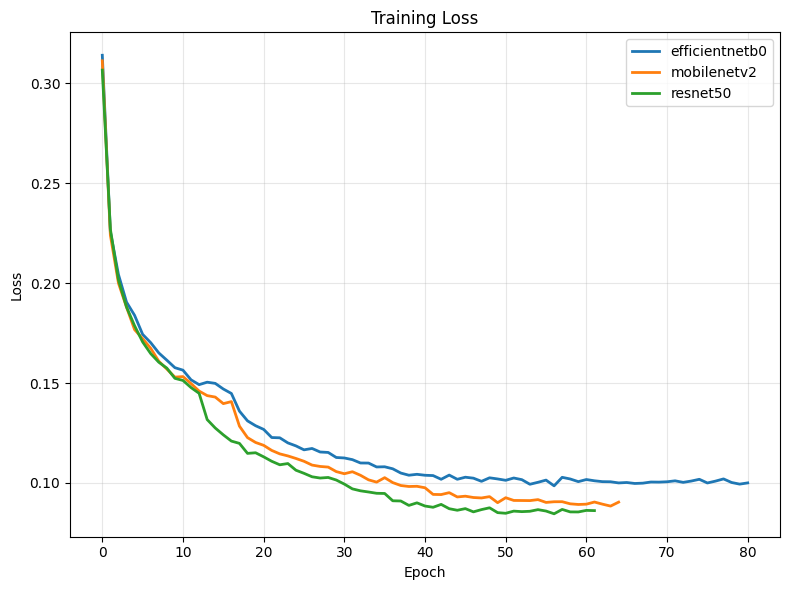

In [16]:
plt.figure(figsize=(8,6))

for model_name, history in histories.items():

    plt.plot(

        history["loss"],

        linewidth=2,

        label=model_name

    )

plt.title("Training Loss")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(

    os.path.join(

        METRICS_DIR,

        "training_loss_comparison.png"

    ),

    dpi=300

)

plt.show()

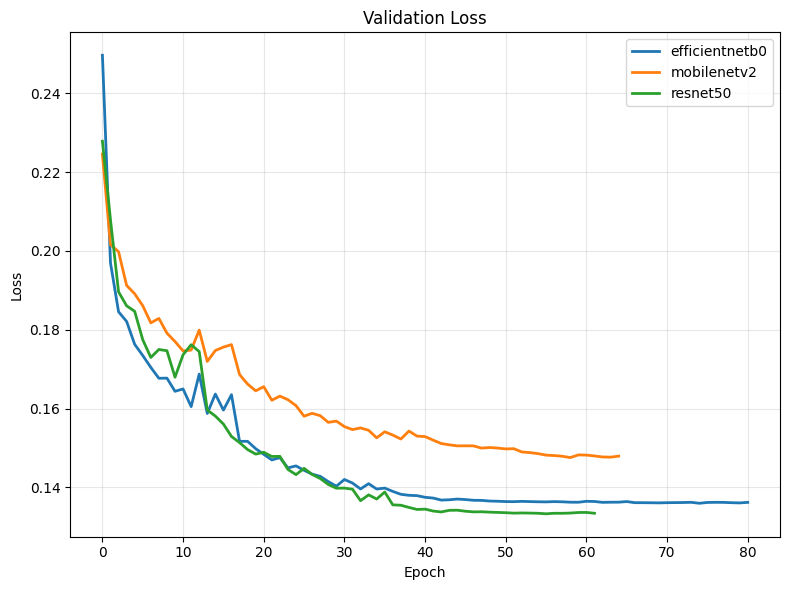

In [17]:
plt.figure(figsize=(8,6))

for model_name, history in histories.items():

    plt.plot(

        history["val_loss"],

        linewidth=2,

        label=model_name

    )

plt.title("Validation Loss")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(

    os.path.join(

        METRICS_DIR,

        "validation_loss_comparison.png"

    ),

    dpi=300

)

plt.show()